In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'PKo'
gitlab_user = 'przemek.kolodziejczyk'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-77a53e4d-7a9d-49be-b475-a142d28e499a;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# PKo

In [2]:
user_issues(ts_user).toPandas()

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10801,[BtcTurk] Rozszerzenie logowania dla adaptera ...,Delivery,Story,High,?,None,2025-07-22 11:30:54.092,13.0,8.5
1,CRYP-10810,[Binance_Futures] Niewłaściwy poziom logowania...,Delivery,Bug,Medium,XS,1,2025-07-18 14:10:03.752,8.5,3.5
2,CRYP-10808,[Platform admin][Vault] Zakodowany path,Delivered,Bug,High,XS,1,2025-07-15 08:11:44.872,2.5,2.0
3,CRYP-10669,[platform-admin] Dodanie obsługi btcturk-hft f...,Delivered,Story,High,XS,1,2025-07-15 08:11:35.362,2.0,0.5
4,CRYP-10815,[Bitbay] Strategia weryfikująca deterministycz...,Delivery,Bug,Medium,XS,1,2025-07-14 08:52:37.032,5.5,3.0
5,CRYP-10712,[Kucoin] Brak danych dla książek dla pojedyńcz...,Delivery,Bug,Medium,XS,1,2025-07-14 08:01:47.634,12.5,2.5
6,CRYP-10430,[AT] Niepoprawne działanie 'selecta' dla strat...,In testing,Bug,Medium,XS,1,2025-07-11 13:09:29.386,14.5,0.5
7,CRYP-10838,[BtcTurk HFT] Błędne rate limity,Delivered,Bug,Highest,XS,1,2025-07-10 08:05:12.085,3.0,1.5
8,CRYP-10811,Bitmart adapter nie potrafi rozwiązać stanu zl...,Delivered,Bug,High,XS,1,2025-07-10 08:05:08.343,5.0,3.0
9,CRYP-10796,[Bitbay] NoSuchElementException podczas przetw...,Delivered,Bug,Medium,XS,1,2025-07-10 08:04:24.689,1.5,1.0


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-06-01,CRYP-10081,Obsługa uprawnień w Platform Admin,Delivery,11.0
1,2025-06-01,CRYP-10082,Restart adapterów feedowych i tradingowych w P...,Delivery,20.5
2,2025-06-01,CRYP-10083,Odświeżanie subskrypcji MDR w Platform Admin p...,In Review,6.5
3,2025-06-01,CRYP-10576,[WebSocket] Wyciągnięcie do biblioteki,Delivered,2.5
4,2025-06-01,CRYP-10641,[Security Definition Provider] Pusta lista prz...,Delivered,4.5
5,2025-06-01,CRYP-10650,[gate.io futures] Dodanie OB best + zmiana ws ...,Delivered,3.5
6,2025-06-01,CRYP-10669,[platform-admin] Dodanie obsługi btcturk-hft f...,Delivered,0.5
7,2025-06-01,CRYP-10676,[Bitso] Implementacja nowego mechanizmu nonce,Delivered,1.0
8,2025-06-01,CRYP-10694,[Kucoin Futures] Purge i subskrybcja dla feedó...,Delivered,0.5
9,2025-06-01,CRYP-10710,Logowanie URL Vault w Platform Admin,Delivered,5.5


In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

In [5]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

In [6]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

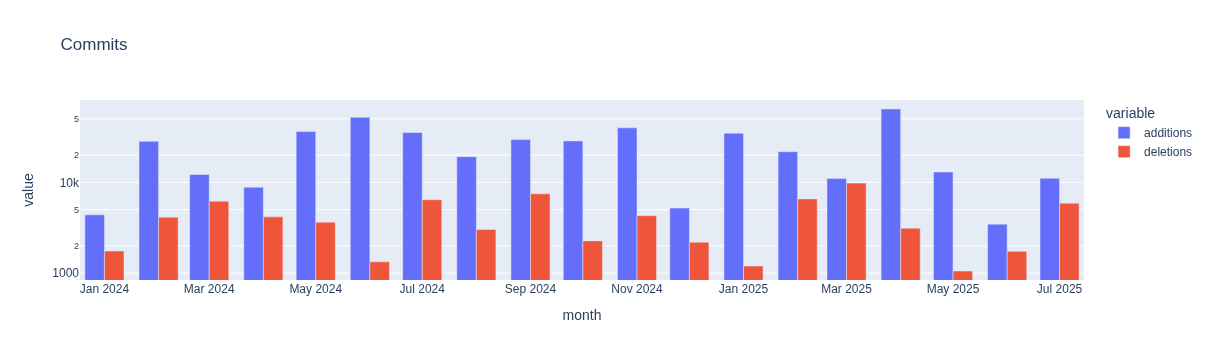

In [7]:
px.bar(user_code_commits('przemyslaw.kolodziejczyk').toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [8]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-06-01,PKo,127.5,32.0,159.5,20.062696
1,2025-05-01,PKo,102.0,22.5,124.5,18.072289
2,2025-04-01,PKo,124.0,44.0,168.0,26.190476
3,2025-03-01,PKo,122.5,39.5,162.0,24.382716
4,2025-02-01,PKo,120.0,40.0,160.0,25.000000
5,2025-01-01,PKo,125.0,34.5,159.5,21.630094
6,2024-12-01,PKo,118.5,27.5,146.0,18.835616
7,2024-11-01,PKo,81.5,71.0,152.5,46.557377
8,2024-10-01,PKo,115.0,61.0,176.0,34.659091
9,2024-09-01,PKo,74.5,93.5,168.0,55.654762


In [9]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-07-01,Spotkania scrumowe,10.0
1,2025-06-01,Spotkania scrumowe,15.5
2,2025-06-01,Developer meetings,11.5
3,2025-06-01,Strategia - uiSpec,0.5
4,2025-06-01,konsultacje - liq calculator,0.5
5,2025-06-01,support,2.0
6,2025-06-01,PAdmin - nowy rest-client,1.0
7,2025-06-01,Bitvavo - nowe api,1.0
8,2025-05-01,Spotkania scrumowe,11.0
9,2025-05-01,Developer meetings,10.5
